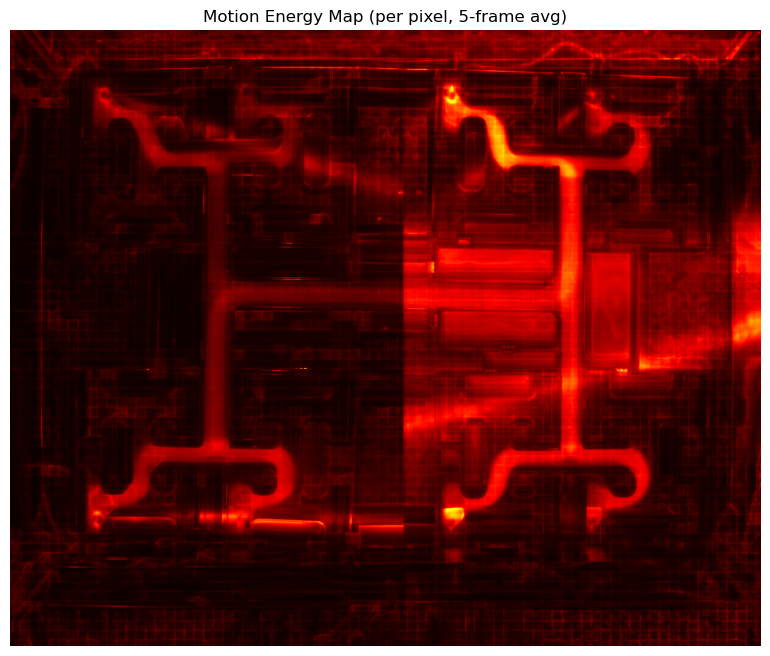

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def motion_energy_map(video_path, cut_minutes=2, avg_window=5):
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cut_frames = int(cut_minutes * 60 * fps)
    start_frame = cut_frames
    end_frame = total_frames - cut_frames

    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
    frames_buffer = []
    for _ in range(avg_window):
        ret, frame = cap.read()
        if not ret:
            cap.release()
            raise ValueError("Could not read enough frames for averaging.")
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        frames_buffer.append(gray)
    prev_avg = np.mean(frames_buffer, axis=0).astype(np.uint8)
    motion_map = np.zeros_like(prev_avg, dtype=np.float64)

    for i in range(start_frame + avg_window, end_frame):
        # Slide the window
        ret, frame = cap.read()
        if not ret:
            break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        frames_buffer.pop(0)
        frames_buffer.append(gray)
        curr_avg = np.mean(frames_buffer, axis=0).astype(np.uint8)
        diff = cv2.absdiff(curr_avg, prev_avg)
        motion_map += diff
        prev_avg = curr_avg

    cap.release()

    # Normalize for visualization
    motion_map_norm = cv2.normalize(motion_map, None, 0, 255, cv2.NORM_MINMAX)
    motion_map_norm = motion_map_norm.astype(np.uint8)

    plt.figure(figsize=(10, 8))
    plt.imshow(motion_map_norm, cmap='hot')
    plt.title('Motion Energy Map (per pixel, 5-frame avg)')
    plt.axis('off')
    plt.show()

    return motion_map, motion_map_norm

# Example usage:
motion_map, motion_map_norm = motion_energy_map(r"C:\Users\Almog\Desktop\Neuropixel_2Cams_Gamma-AnA_July-2025-07-22\videos\NPC1_2025_08_14_13_02_08_stitched_gamma.mp4")


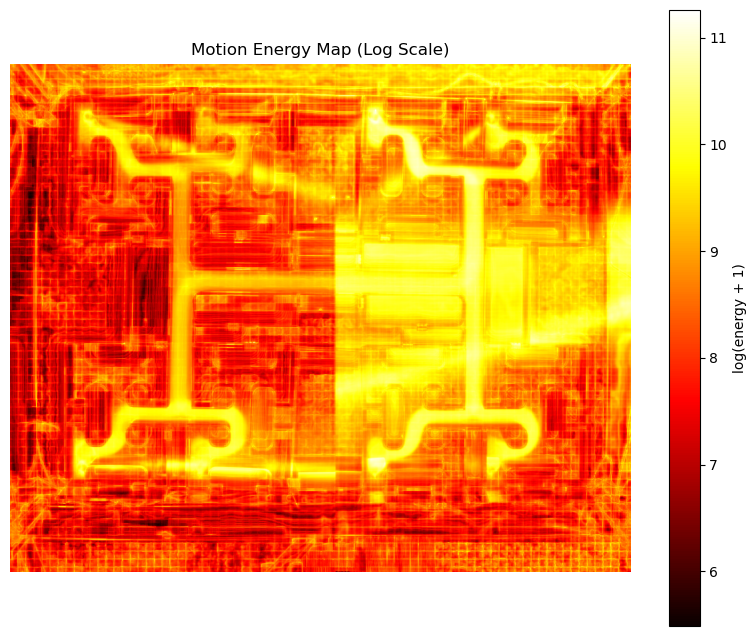

In [5]:
plt.figure(figsize=(10, 8))
plt.imshow(np.log1p(motion_map), cmap='hot')
plt.title('Motion Energy Map (Log Scale)')
plt.axis('off')
plt.colorbar(label='log(energy + 1)')
plt.show()

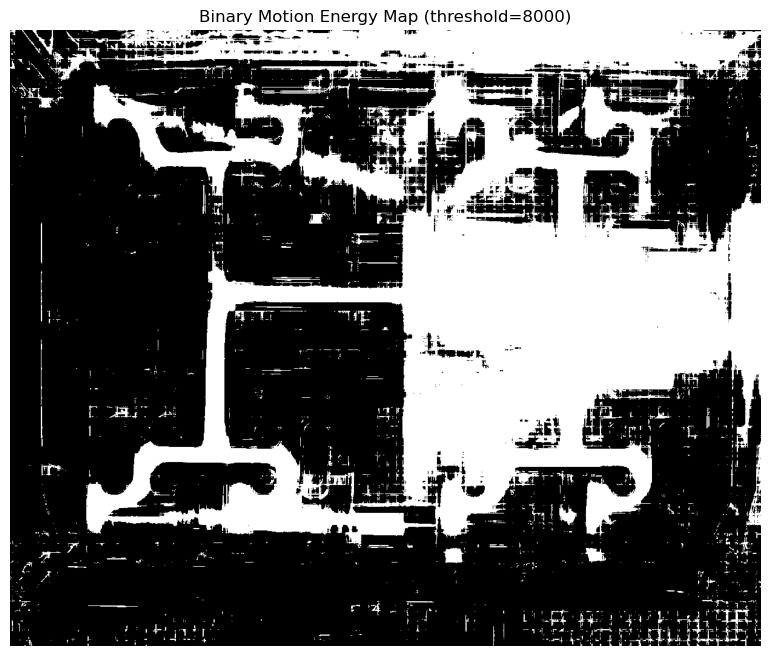

In [13]:
threshold = 8000  # Set your threshold value here
binary_map = (motion_map > threshold).astype(np.uint8) * 255

plt.figure(figsize=(10, 8))
plt.imshow(binary_map, cmap='gray')
plt.title(f'Binary Motion Energy Map (threshold={threshold})')
plt.axis('off')
plt.show()